# 02 - What ethylene glycol costs to eat

PET breaks into two monomers and the consortium gives one to each strain: Pp-T takes
terephthalate, Pp-E takes ethylene glycol. Bao et al. found the consortium builds up more
glycolate than the single generalist does, and glycolate is on the ethylene glycol side.

Before asking why that side leaks, I want to know whether it's a harder substrate to
begin with, and if so, what makes it hard.

I feed the model each substrate on its own, at matched carbon, and compare. Protocatechuate
stands in for the terephthalate route, since terephthalate isn't in iJN1463 and
protocatechuate is the first intermediate the native pathway picks up. Glucose is the
control, because that's what the model was built and validated on.

Short answer: ethylene glycol needs almost twice the oxygen per carbon that the aromatic
route does, and it's the first to suffer when oxygen runs short.

In [1]:
import sys
sys.path.append("../src")
from putida import *

from cobra.flux_analysis import pfba, flux_variability_analysis
import pandas as pd
import matplotlib.pyplot as plt
import os

model = load_model()
print(model.id, "|", len(model.reactions), "reactions |", len(model.genes), "genes")

iJN1463 | 2929 reactions | 1462 genes


## The chemistry first

Degree of reduction counts electrons per carbon atom: `gamma = 4C + H - 2O`. The cell has
to pull those electrons off and hand them to oxygen before it can use the carbon for
anything. More reduced substrate means more electrons arriving per carbon, and more
respiration needed to deal with the same amount of food.

This one line of arithmetic predicts the rest of the notebook.

In [2]:
SUBSTRATES = [
    (EX_GLYCOL,  "ethylene glycol"),
    (EX_PCA,     "protocatechuate"),
    (EX_GLUCOSE, "glucose (control)"),
]

print(f"{'substrate':<20} {'formula':<10} {'gamma':>7} {'per carbon':>12}")
for ex, label in SUBSTRATES:
    met = model.metabolites.get_by_id(ex.replace("EX_", "", 1))
    e = met.elements
    C, H, O = e.get("C", 0), e.get("H", 0), e.get("O", 0)
    gamma = 4 * C + H - 2 * O
    print(f"{label:<20} {met.formula:<10} {gamma:>7} {gamma / C:>12.2f}")

substrate            formula      gamma   per carbon
ethylene glycol      C2H6O2          10         5.00
protocatechuate      C7H5O4          25         3.57
glucose (control)    C6H12O6         24         4.00


## Matching the carbon

10 mmol of glucose is 60 mmol of carbon. 10 mmol of ethylene glycol is 20. Comparing the
same molar amounts compares two different amounts of food. `matched_carbon()` turns a
carbon budget into the right uptake rate for each molecule.

Two method notes, both of which matter if someone checks this.

**pFBA instead of plain FBA.** A flux balance problem usually has many internal flux
patterns that all give the same optimal growth. Plain `optimize()` hands back whichever
one the solver happened to find, so internal numbers like NADH production aren't
reproducible between runs. `pfba` breaks the tie by minimising total flux and returns one
defined answer.

**Ranges instead of single numbers for anything internal.** Even with pFBA a single value
hides how much freedom the model has. The FVA columns show the range each flux can take
while growth stays within 0.1% of optimal. Narrow range means the model is forced to that
value. Wide range means it's a choice, not a result.

In [3]:
CARBON = 70.0   # mmol carbon per gDW per hour, same for every substrate

rows = []
for ex, label in SUBSTRATES:
    uptake = matched_carbon(model, ex, CARBON)
    with model:
        set_carbon(model, {ex: uptake}, o2=100.0)
        sol = pfba(model)
        fva = flux_variability_analysis(
            model, reaction_list=[R_NADH16, EX_O2], fraction_of_optimum=0.999
        )
        rows.append({
            "substrate":   label,
            "uptake":      round(uptake, 2),
            "growth":      round(sol.fluxes[BIOMASS], 4),
            "O2_per_C":    round(-sol.fluxes[EX_O2] / CARBON, 3),
            # FVA reports the exchange as negative for uptake, so flip the signs
            "O2_lo":       round(-fva.loc[EX_O2, "maximum"], 1),
            "O2_hi":       round(-fva.loc[EX_O2, "minimum"], 1),
            "NADH16_lo":   round(fva.loc[R_NADH16, "minimum"], 1),
            "NADH16_hi":   round(fva.loc[R_NADH16, "maximum"], 1),
        })

matched = pd.DataFrame(rows)
print(f"All three fed {CARBON:.0f} mmol carbon per gDW per hour, oxygen generous.\n")
print(matched.to_string(index=False))

os.makedirs("../results", exist_ok=True)
matched.to_csv("../results/matched_carbon.csv", index=False)

All three fed 70 mmol carbon per gDW per hour, oxygen generous.

        substrate  uptake  growth  O2_per_C  O2_lo  O2_hi  NADH16_lo  NADH16_hi
  ethylene glycol   35.00  0.8435     0.745   52.1   52.2       30.2       30.6
  protocatechuate   10.00  0.8577     0.415   29.0   29.1       20.6       21.1
glucose (control)   11.67  1.1436     0.315   22.0   22.1       26.5       27.8


Growth per carbon is nearly identical for ethylene glycol and protocatechuate, so on
carbon alone they look equally good. Oxygen is where they split: 0.745 mmol O2 per mmol
carbon against 0.415, and that figure is pinned to a fraction of a percent, so it comes
from the stoichiometry rather than from the solver.

The NADH range is wider and glucose sits inside the gap. That's why I quote oxygen and
not NADH.

## Now tighten the oxygen

If ethylene glycol's cost is paid in oxygen, restricting oxygen should hurt it first.

This also sets up the next notebooks: `GLYCTO1`, the enzyme that clears glycolate,
consumes O2 itself and makes hydrogen peroxide. So oxygen supply and glycolate disposal
aren't independent.

In [4]:
O2_LEVELS = [100, 60, 50, 40, 30, 25, 20, 15, 10, 7.5, 5, 2.5, 1]

records = []
for ex, label in SUBSTRATES:
    uptake = matched_carbon(model, ex, CARBON)
    for o2 in O2_LEVELS:
        with model:
            set_carbon(model, {ex: uptake}, o2=o2)
            sol = model.optimize()
            growth = sol.objective_value if sol.status == "optimal" else 0.0
            records.append({"substrate": label, "o2": o2, "growth": round(growth, 4)})

sweep = pd.DataFrame(records)
table = (sweep.pivot(index="o2", columns="substrate", values="growth")
              .sort_index(ascending=False))

print("Growth rate (1/h) as the oxygen cap tightens, carbon held constant.\n")
print(table.to_string())

sweep.to_csv("../results/oxygen_sweep.csv", index=False)
print("\nsaved ../results/oxygen_sweep.csv")

Growth rate (1/h) as the oxygen cap tightens, carbon held constant.

substrate  ethylene glycol  glucose (control)  protocatechuate
o2                                                            
100.0               0.8435             1.1436           0.8577
60.0                0.8435             1.1436           0.8577
50.0                0.8088             1.1436           0.8577
40.0                0.6457             1.1436           0.8577
30.0                0.4825             1.1436           0.8577
25.0                0.4009             1.1436           0.7372
20.0                0.3193             1.0481           0.5879
15.0                0.2378             0.7931           0.4386
10.0                0.1562             0.5382           0.2893
7.5                 0.1154             0.4108           0.2146
5.0                 0.0746             0.2730           0.1399
2.5                 0.0338             0.1299           0.0653
1.0                 0.0093             0.0441    

In [5]:
# fraction of maximum growth retained, which is the comparable quantity
# across substrates that have different maxima to begin with
retained = (table / table.loc[100]).round(3)
print("Fraction of each substrate's own maximum growth retained.\n")
print(retained.to_string())

print()
for label in table.columns:
    print(f"{label:<20} {retained.loc[25, label]*100:5.1f}% at O2=25   "
          f"{retained.loc[15, label]*100:5.1f}% at O2=15")

Fraction of each substrate's own maximum growth retained.

substrate  ethylene glycol  glucose (control)  protocatechuate
o2                                                            
100.0                1.000              1.000            1.000
60.0                 1.000              1.000            1.000
50.0                 0.959              1.000            1.000
40.0                 0.766              1.000            1.000
30.0                 0.572              1.000            1.000
25.0                 0.475              1.000            0.860
20.0                 0.379              0.916            0.685
15.0                 0.282              0.694            0.511
10.0                 0.185              0.471            0.337
7.5                  0.137              0.359            0.250
5.0                  0.088              0.239            0.163
2.5                  0.040              0.114            0.076
1.0                  0.011              0.039            0.

saved ../figures/growth_vs_oxygen.png


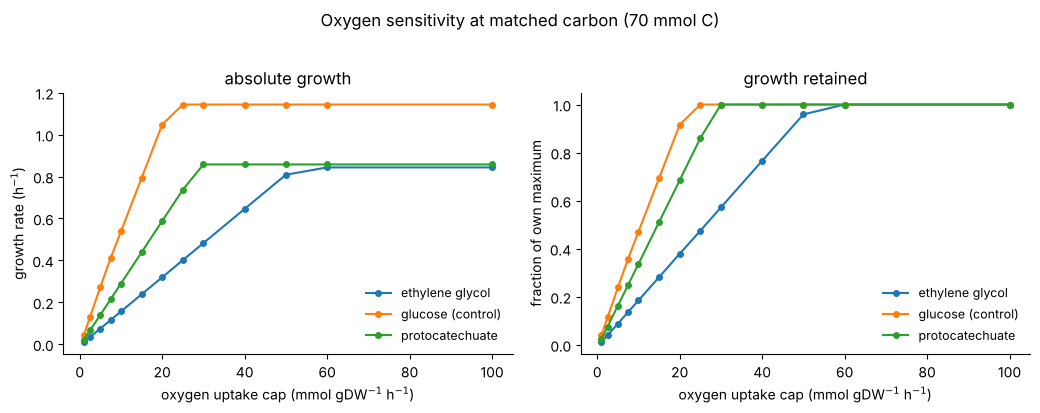

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.0))

for label in table.columns:
    axes[0].plot(table.index, table[label], marker="o", markersize=4, label=label)
    axes[1].plot(retained.index, retained[label], marker="o", markersize=4, label=label)

axes[0].set_ylabel("growth rate (h$^{-1}$)")
axes[0].set_title("absolute growth")
axes[1].set_ylabel("fraction of own maximum")
axes[1].set_title("growth retained")

for ax in axes:
    ax.set_xlabel("oxygen uptake cap (mmol gDW$^{-1}$ h$^{-1}$)")
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, fontsize=9)

fig.suptitle(f"Oxygen sensitivity at matched carbon ({CARBON:.0f} mmol C)", y=1.02)
fig.tight_layout()

os.makedirs("../figures", exist_ok=True)
fig.savefig("../figures/growth_vs_oxygen.png", dpi=200, bbox_inches="tight")
print("saved ../figures/growth_vs_oxygen.png")

## Conclusion

1. Ethylene glycol is the most reduced substrate here, 5.00 electrons per carbon against
   protocatechuate's 3.57.
2. The cost shows up in oxygen, not carbon. At matched carbon both support about the same
   growth, but ethylene glycol wants 1.8 times the oxygen per carbon, and FVA says that
   ratio is forced rather than chosen.
3. Restricting oxygen hurts ethylene glycol first. The aromatic route holds full growth
   down to an O2 cap of 30, by which point ethylene glycol has lost over 40%.

So the ethylene glycol branch is the one exposed to anything that limits respiration.
That's Pp-E's branch, and it's the branch glycolate sits on.

**Limitations.** Protocatechuate is a stand-in, and the real terephthalate route adds a
dioxygenase step that burns reducing equivalents, so Pp-T's true cost is understated here.
iJN1463 is wild-type KT2440, not Bao's engineered strains. And a fixed uptake with a fixed
oxygen cap is a steady state, while Bao ran batch cultures where both change by the hour.

**Next.** Notebook 03 tests the explanation Bao actually gave, that succinate is the
carbon sink.